# Modelado y evaluación de Churn — Telco Customer Churn

**Objetivo:** entrenar un clasificador binario para identificar clientes que abandonan el servicio (`Churn=Yes`) y evaluar el resultado con las métricas de la consigna.

Este notebook sigue el flujo `carga → limpieza mínima → split 80/20 → preprocesamiento y modelo → evaluación`. El preprocesamiento se ajusta dentro del pipeline y únicamente con el conjunto de entrenamiento.


## 1. Problema y dataset

Cada fila representa un cliente de una empresa de telecomunicaciones. La variable objetivo es `Churn`: `Yes` indica que abandonó el servicio y `No` que permaneció.

Se utiliza el dataset **Telco Customer Churn** de BlastChar, disponible en [Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn). Una copia del CSV está en `data/WA_Fn-UseC_-Telco-Customer-Churn.csv`.

La pregunta práctica es: **¿qué clientes que podrían abandonar conviene identificar para ofrecerles una acción de retención?**


## 2. Librerías y carga de datos

Las transformaciones aprendidas por el modelo se mantienen dentro de Scikit-Learn. `pandas` carga y revisa la tabla; `matplotlib` dibuja la matriz de confusión.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
DATA_PATH = Path("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"No se encontró el dataset en {DATA_PATH}. "
        "Ejecuta el notebook desde la carpeta pre-entregamd10."
    )

print("Dataset:", DATA_PATH)


Dataset: data\WA_Fn-UseC_-Telco-Customer-Churn.csv


In [2]:
datos = pd.read_csv(DATA_PATH)

print(f"Filas: {datos.shape[0]:,} | Columnas: {datos.shape[1]}")
display(datos.head())

datos.info()


Filas: 7,043 | Columnas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
# Revisamos la proporción de las clases y los faltantes más frecuentes.
proporcion_churn = datos["Churn"].value_counts(normalize=True).rename("proporción")
display(proporcion_churn.to_frame())

faltantes = datos.isna().sum().sort_values(ascending=False).head(10)
display(faltantes.rename("valores faltantes").to_frame())


,proporción
Churn,
No,0.73463
Yes,0.26537


,valores faltantes
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


## 3. Preparación mínima

- `customerID` identifica a cada cliente, pero no aporta una regla generalizable para predecir el abandono; se excluye de las variables predictoras.
- `TotalCharges` puede venir como texto porque algunas celdas están vacías. Se convierte a número; las celdas vacías pasan a `NaN` y el imputador las resolverá más adelante.
- `Churn` se transforma en una etiqueta binaria: `No → 0` y `Yes → 1`.

Estas operaciones solo cambian formato o seleccionan columnas. No calculan medianas, escalas ni categorías a partir del conjunto completo.


In [4]:
datos_modelo = datos.drop(columns=["customerID"]).copy()
datos_modelo["TotalCharges"] = pd.to_numeric(
    datos_modelo["TotalCharges"], errors="coerce"
)
datos_modelo["Churn"] = datos_modelo["Churn"].map({"No": 0, "Yes": 1})

if datos_modelo["Churn"].isna().any():
    raise ValueError("La columna Churn contiene etiquetas distintas de Yes/No.")

print("Valores faltantes en TotalCharges tras convertir a número:",
      int(datos_modelo["TotalCharges"].isna().sum()))
display(datos_modelo["Churn"].value_counts().rename(index={0: "No churn (0)", 1: "Churn (1)"}).to_frame("clientes"))


Valores faltantes en TotalCharges tras convertir a número: 11


,clientes
Churn,
No churn (0),5174
Churn (1),1869


## 4. División entrenamiento/prueba

Se reserva el **20 %** para la prueba y se entrena con el 80 % restante. `stratify=y` conserva aproximadamente la proporción de clientes con y sin churn en los dos conjuntos; `random_state=42` hace reproducible la división.

El split ocurre antes de ajustar cualquier imputador, escalador o codificador. Esta separación evita que el preprocesamiento aprenda estadísticas del conjunto de prueba (*data leakage*).


In [5]:
X = datos_modelo.drop(columns=["Churn"])
y = datos_modelo["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

columnas_numericas = X_train.select_dtypes(include="number").columns.tolist()
columnas_categoricas = X_train.select_dtypes(exclude="number").columns.tolist()

print(f"Entrenamiento: {len(X_train):,} filas")
print(f"Prueba: {len(X_test):,} filas")
print("Variables numéricas:", columnas_numericas)
print("Variables categóricas:", columnas_categoricas)


Entrenamiento: 5,634 filas
Prueba: 1,409 filas
Variables numéricas: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Variables categóricas: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 5. Preprocesamiento y modelo

Se elige **Regresión Logística** porque es un modelo de clasificación sencillo de explicar y permitido por la consigna. `class_weight="balanced"` da más peso a la clase menos frecuente durante el ajuste; esto es una decisión inicial para no ignorar a los clientes que abandonan.

| Tipo de variable | Tratamiento |
|---|---|
| Numérica | Imputar valores faltantes con mediana → escalar con `StandardScaler` |
| Categórica | Imputar con el valor más frecuente → codificar con `OneHotEncoder` |

El `Pipeline` conecta el preprocesamiento con el clasificador. Al llamar `fit` con `X_train`, todos los parámetros se aprenden solo de entrenamiento.


In [6]:
pipeline_numerico = Pipeline(
    steps=[
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler()),
    ]
)

pipeline_categorico = Pipeline(
    steps=[
        ("imputador", SimpleImputer(strategy="most_frequent")),
        ("codificador", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocesador = ColumnTransformer(
    transformers=[
        ("numericas", pipeline_numerico, columnas_numericas),
        ("categoricas", pipeline_categorico, columnas_categoricas),
    ]
)

modelo = Pipeline(
    steps=[
        ("preprocesador", preprocesador),
        (
            "clasificador",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

modelo.fit(X_train, y_train)
predicciones = modelo.predict(X_test)
print("Modelo entrenado y predicciones generadas sobre el conjunto de prueba.")


Modelo entrenado y predicciones generadas sobre el conjunto de prueba.


## 6. Métricas sobre el conjunto de prueba

La consigna pide Accuracy, Precision, Recall, F1-Score y matriz de confusión. Para Precision, Recall y F1, usamos como clase positiva `Churn=1`: nos interesa medir explícitamente qué tan bien se detectan los clientes que abandonan.


In [7]:
metricas = pd.Series(
    {
        "Accuracy": accuracy_score(y_test, predicciones),
        "Precision (Churn=1)": precision_score(y_test, predicciones, pos_label=1, zero_division=0),
        "Recall (Churn=1)": recall_score(y_test, predicciones, pos_label=1, zero_division=0),
        "F1-Score (Churn=1)": f1_score(y_test, predicciones, pos_label=1, zero_division=0),
    },
    name="Resultado",
)
display(metricas.to_frame().round(3))

print("Reporte por clase:")
print(
    classification_report(
        y_test,
        predicciones,
        labels=[0, 1],
        target_names=["No churn (0)", "Churn (1)"],
        zero_division=0,
    )
)


,Resultado
Accuracy,0.738
Precision (Churn=1),0.504
Recall (Churn=1),0.783
F1-Score (Churn=1),0.614


Reporte por clase:
              precision    recall  f1-score   support

No churn (0)       0.90      0.72      0.80      1035
   Churn (1)       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



,Predicho: No churn (0),Predicho: Churn (1)
Real: No churn (0),747,288
Real: Churn (1),81,293


Falsos negativos (clientes que abandonan y el modelo no detecta): 81
Falsos positivos (clientes señalados que no abandonan): 288


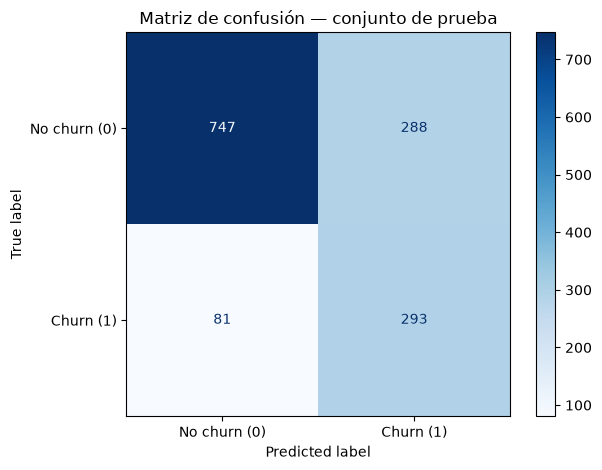

In [8]:
matriz = confusion_matrix(y_test, predicciones, labels=[0, 1])
matriz_df = pd.DataFrame(
    matriz,
    index=["Real: No churn (0)", "Real: Churn (1)"],
    columns=["Predicho: No churn (0)", "Predicho: Churn (1)"],
)
display(matriz_df)

tn, fp, fn, tp = matriz.ravel()
print(f"Falsos negativos (clientes que abandonan y el modelo no detecta): {fn}")
print(f"Falsos positivos (clientes señalados que no abandonan): {fp}")

ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["No churn (0)", "Churn (1)"],
).plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión — conjunto de prueba")
plt.tight_layout()
plt.show()


## 7. Interpretación: falsos negativos y decisión de negocio

**Para este problema priorizamos Recall de la clase `Churn=1`.** Recall responde: de todos los clientes que realmente abandonaron, ¿qué proporción logró detectar el modelo?

Un **falso negativo** ocurre cuando el cliente sí abandona (`Churn=1`), pero el modelo predice que se quedará (`0`). La empresa pierde la oportunidad de contactarlo a tiempo con soporte, una oferta o un cambio de plan; por eso este error puede tener un costo alto en ingresos y retención.

También importa el costo contrario. Un **falso positivo** es un cliente señalado como posible baja que finalmente permanece. Contactarlo puede consumir presupuesto o generar una oferta innecesaria. Si se intenta aumentar Recall, pueden crecer esos falsos positivos y bajar Precision; hay que decidir el equilibrio según el costo de la campaña.

Accuracy por sí sola puede resultar engañosa cuando la clase `Churn=1` es minoritaria: acertar muchos clientes que permanecen no garantiza detectar a quienes se van. Por eso miramos Recall, Precision, F1 y la matriz de confusión en conjunto. **Recall es la métrica prioritaria para el objetivo de retención, no una métrica universal para cualquier negocio.**


## 8. Conclusión

El notebook deja una línea base reproducible para clasificación de Churn: las transformaciones se ajustan dentro del pipeline sobre entrenamiento, y las métricas se calculan una sola vez sobre el conjunto de prueba. Si se quisiera mejorar el sistema, el siguiente paso sería comparar umbrales o modelos teniendo en cuenta el costo real de cada falso negativo y falso positivo.
